## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [13]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nina Breen

**Date:** 10/19/26

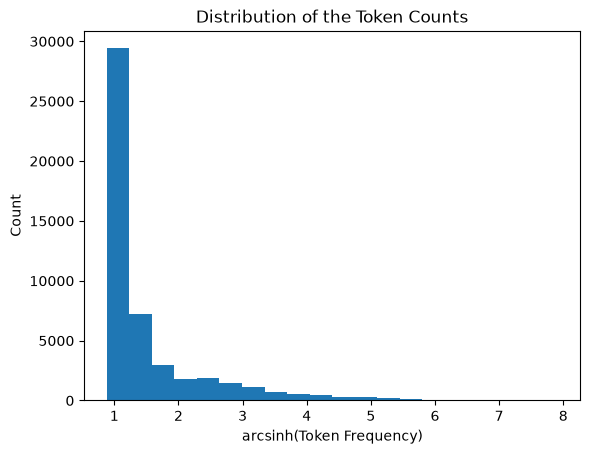

In [ ]:
# Your Phase 1 solution to the problem goes here.
# Q1 - making histogram of the occurance of tokens
import matplotlib.pyplot as plt
import numpy as np

token_counts = list(token_count.values()) # selecting only the values and then making that into a list

arcsinh_token_counts = np.arcsinh(token_counts) # applying arcsinh because the data is skewed

plt.hist(arcsinh_token_counts, bins = 20)
plt.title('Distribution of the Token Counts')
plt.xlabel('arcsinh(Token Frequency)')
plt.ylabel('Count')

plt.show()

# This histogram shows that most token appear at a lower frequency. Even after normalization, there seems to still be a skew meaning that there are a lot of tokens happening at lower frequencies. 


**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [28]:
import pandas as pd
df = pd.read_parquet('./data/Phishing_clean.parquet')

# splitting the data 80/20:
from sklearn.model_selection import train_test_split
eval_x_raw = df.drop(columns = ['Email Type'])
eval_y = df['Email Type']
(x_train, x_valid, y_train, y_valid,) = train_test_split(eval_x_raw, eval_y, test_size = 0.20, random_state = 7)



In [29]:
# regression of y - what is R^2 on the test set and training set
from sklearn.linear_model import LinearRegression
sk_fit = LinearRegression().fit(x_train, y_train)

print("R-squared - training set:", round(sk_fit.score(x_train, y_train), 4))
print("R-squared - test set:", round(sk_fit.score(x_valid, y_valid), 4))


R-squared - training set: 0.7657
R-squared - test set: 0.6682


In [ ]:
# What word has the largest coefficients in absolute value and most strongly influence predictions:
coefficients = sk_fit.coef_
word_names = eval_x_raw.columns

coef_df = pd.DataFrame({
    'Word': word_names,
    'Coefficient': coefficients,
    'Absolute_Coef': np.abs(coefficients)
})

top_words = coef_df.sort_values(by = 'Absolute_Coef', ascending=False).head(5)
print('Top words influencing predictions:\n', top_words)

# The word that has the largest coefficient and strongest influence on the prediction is helvetica. Because the non-absolute coefficient is positive, that means that this predicts the email to be a phishing scam email.

Top words influencing predictions:
                    Word  Coefficient  Absolute_Coef
1406         helvetica,     1.024227       1.024227
1504  background-image:    -1.018343       1.018343
1047         font-size:    -0.997077       0.997077
2094           #000000;     0.924223       0.924223
2666           #331f30;     0.924223       0.924223


**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

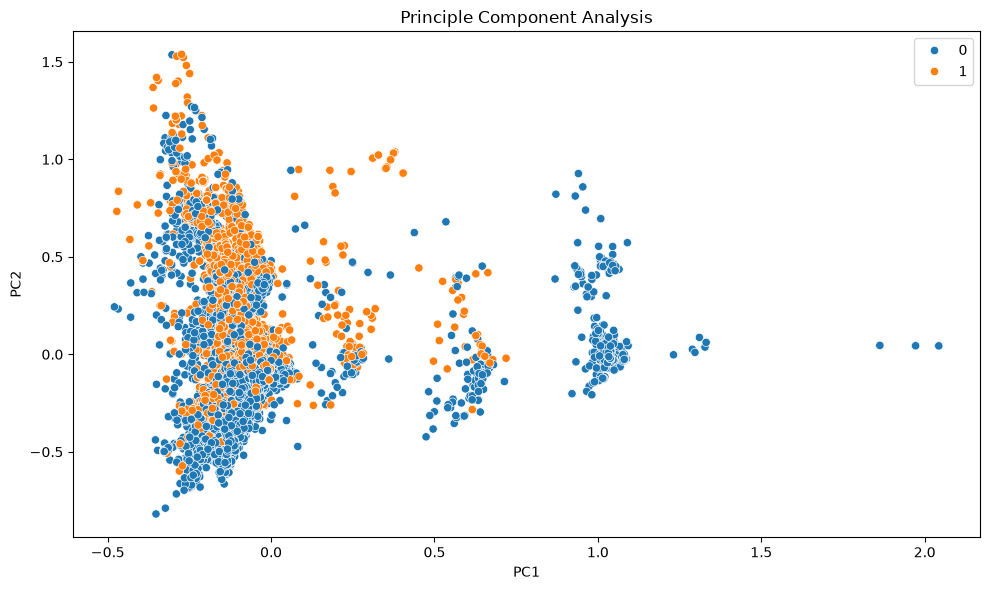

In [ ]:
# the email column is already removed in the variable exal_x_raw // two components means that n = 2
from sklearn.decomposition import PCA
import seaborn as sns

pca_emails = PCA(n_components = 2).fit(eval_x_raw)
x_pca_sklearn = pca_emails.transform(eval_x_raw)

# making a df to hold the pca results so we can plot it
pca_df = pd.DataFrame(data = x_pca_sklearn, columns = ['PC1', 'PC2'])
pca_df['Email Type'] = eval_y.values

# plotting the scatter plot
fig, ax = plt.subplots(figsize = (10,6))
sns.scatterplot(
    data = pca_df, 
    x = 'PC1', 
    y = 'PC2',
    hue = 'Email Type',
    ax = ax)

ax.set_title('Principle Component Analysis')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend()

plt.tight_layout()
plt.show()

# There is a large clump of scam and legitamite emails on the left side of the graph. This means that 2 components do not capture enough variance to differentiate the email types.
# However, there is a large group of legitamite emails with no scam emails on the right side of the graph indicating that high scored on PC1 indicate that the emails are legitament. 


**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [ ]:
# running PCA analysis
pca_emails_multiple = PCA(n_components=2610).fit(eval_x_raw)
x_pca_emails_multiple = pca_emails_multiple.transform(eval_x_raw)

# splitting the pca data:
x_train_pca, x_valid_pca, y_train_pca, y_valid_pca = train_test_split(x_pca_emails_multiple, eval_y, test_size = 0.20, random_state = 7)

# ftting the linear regression model + getting R^2 values
pca_lr_model = LinearRegression().fit(x_train_pca, y_train_pca)

print("R-squared - training set:", round(pca_lr_model.score(x_train_pca, y_train_pca), 4))
print("R-squared - test set:", round(pca_lr_model.score(x_valid_pca, y_valid_pca), 4))

# Q2 R-squared - training set for linear regression: 0.7657
# Q2 R-squared - test set for linear regr: 0.6682

#

R-squared - training set: 0.7647
R-squared - test set: 0.6721


In [ ]:
# data is already split from Q2 so reusing that

# fitting pca based on the training set:
pca_emails_multiple = PCA(n_components = 2610).fit(x_train)
x_train_pca = pca_emails_multiple.transform(x_train)

#doing pca on the test set:
x_valid_pca = pca_emails_multiple.transform(x_valid)

# linear regression:
pca_lr_model = LinearRegression().fit(x_train_pca, y_train)

print("R-squared - training set:", round(pca_lr_model.score(x_train_pca, y_train), 4))
print("R-squared - test set:", round(pca_lr_model.score(x_valid_pca, y_valid), 4))

# The test set R^2 increased slightly between the linear regression on the original data vs the pca (0.6682 for the original data and 0.6718 for the pca).
# Additionally, the R^ squared value for the training set decreased slightly (0.7657 for the original data and 0.7648 for the pca).
# This means that the test set increased in correctness while the training set decreased meaning it is picking up less random noise. 


R-squared - training set: 0.7648
R-squared - test set: 0.6718


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.


In [ ]:
# There are multiple advantages of using principal components to run the high-dimensional regression.
# By using pca, you are able to filter out noise a lot easier. By using not all PCA values, you 
# reduce the amount of noise that is in the analysis and reduce linear regression model fitting 
# just because of noise. There is also less overfitting, this is because there are less dimensions and the model
# can focus on just signals. This helps the test set and unseen data have more accurate predictions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]